In [ ]:
import math
dir(math)

##  Dokumentation eigener Module
Kommentare als Verständnishilfe.

`# Einzeiliger Kommentar`

```
"""Mehrzeiliger
Kommentar"""
```
- Üblich: Allgemeine Beschreibung des
Moduls durch Docstring zu Beginn der
Moduldatei.
- Funktionen und Quellcode werden wie üblich dokumentiert.

```python
class MeineKlasse:
"""Beispiel fuer Docstrings.
Diese Klasse zeigt, wie Docstrings verwendet
werden.
"""
pass
def MeineFunktion():
"""Diese Funktion macht nichts.
Im Ernst, diese Funktion macht wirklich nichts.
"""
pass
```
### Packages
Packages fassen mehrerer Module in einem Paket (package) zusammen.
Der praktische Nutzen ist die Strukturierung von Modulen.
- Notwendig: Datei mit dem Namen __init__.py im Package
- Kann leer sein oder Python-Code enthalten, der beim Import des Paketes ausgeführt werden soll.
- Typischerweise importiert man keine ganzen Packages:
```python
from package import module_a, module_b
module_a.func()
module_b.func()
```


### Aufgabe 1
Schreiben Sie ein Modul `string_helper`, das eine Funktion enthält, die einen
gegebenen String invertiert (z.B. 12345 → 54321)
Rufen Sie die Funktion aus der mit einem Text Ihrer Wahl auf.

# NumPy

`numpy`: Paket zur Speicherung von Daten in `ndarrays` (Vektoren, Matrizen, Tensoren)

**Warum ist `numpy` schneller als Python**: Python speichert Daten dort, wo grade Platz ist. `numpy` versucht 
zusammenhängende Speicherbereiche zu allozieren (localiity of reference). Außerdem ist es auf die neuesten 
CPU-Architekturen optimiert. 

**hello word - Examples**:
```python
import numpy as np 
vec = np.array([1, 2, 3, 4, 5])                                         # Vektor
mat = np.array([[1, 2, 3], [4, 5, 6]])                                  # Matrix
tensor = np.array([[[1, 2, 3], [4, 5, 6]], [[1, 2, 3], [4, 5, 6]]])     # Tensor
print(vec)
print(f'Shape eines ndarray: {tensor.shape}')                           # (2,2,3)
```
**Shape** = Größe pro Dimensionen 

Tensor der Stufe 3 / `ndarray` von Rang 3 könnte beispielsweise ein Farbbild sein. Shape: (3,1920,1080) bedeutet 3 
Farbkanäle, jeweils 1920 Pixel in x Richtung und 1080 Pixel in y Richtung.

Zugriff und Slicing funktionieren ähnlich wie in Matlab oder Python:
```python
import numpy as np
arr = np.array([[1,2,3,4,5], [6,7,8,9,10]])
print(f'Element in Zeile 2 Spalte 5 ist: {arr[1, 4]}')      # 10
print(f'Letztes Element der zweiten Zeile: {arr[1, -1]}')   # 10 
print(f'Elemente 1 bis 3 von Zeile 1: {arr[0, 0:3]}')       # [1 2 3]
``` 
Initialisieren von `ndarrays`:
```python
import numpy as np
shape = (2,3,4)
ones = np.ones(shape)           # Einsen
zeros = np.zeros(shape)         # Nullen
print(ones)
```

Rechnen mit `ndarrays`: 
- **elementweise** ist hier der default
- Matrixoperation über die entsprechenden Funktionen
```python
a = np.array([[1, 2, 3], [4, 5, 6]])
print(a + 10)                           # [[11 12 13]
                                        # [14 15 16]]
print(a**2)                             # [[ 1 4 9]
                                        # [16 25 36]]
b = np.full((2, 3), 3)
print(a − b)                            # [[−2 −1 0]
                                        # [ 1 2 3]]
print(a*b)                              # [[ 3 6 9]
                                        # [12 15 18]]
c = np.transpose(a)                     # Transponierte Matrix
print(np.matmul(a, c))                  # [[14 32]
                                        # [32 77]]
```

### Aufgabe 2
Erzeugen Sie eine 2x3 - Matrix, bei der alle Einträge 3 sind, ändern Sie Element (0,1) auf 1 und multiplizieren Sie 
diese mit einer Matrix, der 3x3-Vandermonde-Matrix (https://numpy.org/doc/stable/reference/routines.array-creation.html) 
mit [1,2,3] 
Printen Sie die resultierende Matrix und deren Shape. 

### Broadcasting
Broadcasting = Operationen auf `ndarray`s ausführen, die erstmal nicht kompatibel sind

**Regel:**
Vergleich der Shapes von hinten / rechts nach vorne / links. Zwei Arrays sind kompatibel, wenn
- die Dimension gleich ist oder
- eine Array eine Dimension 1 hat
- Größe des resultierenden Arrays: maximale Größe entlang jeder Dimension der Eingabearrays
- Unterschiedlicher Rang möglich, solange alle elementweisen Vergleiche der Dimensionen kompatibel

Beispiel:
- A: &nbsp;&nbsp;&nbsp;&nbsp;15 × 3 × 5
- B: &nbsp;&nbsp;&nbsp;&nbsp;15 × 1 × 5
- A*B: 15 × 3 × 5

- A: &nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;6 × 1
- B: &nbsp;&nbsp;&nbsp;&nbsp;7 × 1 × 5
- A*B: 7 × 6 × 5

```python
A = np.ones((6,3))
B = np.ones((2,1,3))
(A + B).shape           # (2,6,3)
```

### Reshaping
Verschiedene Methoden des Reshapings:
1. Instanziierung eines neuen Arrays mit der geforderten Shape
2. Virtuelles Reshapen / View - das Array verhält sich nach Außen wie ein neues Objekt mit der gewünschten shape, 
intern liegen die Daten in der ursprünglichen Form vor. 

**Warum das Ganze?** Reshapen kostet Zeit gerade bei großen Arrays viel Zeit. Ein Verhalten wie bei einer anderen 
Shape zu imitieren ist da um Größenordnungen schneller. 
```python
import numpy as np
arr = np.array([1, 2, 3, 4, 5, 6, 7, 8])
print(arr.reshape(2, 4))                # [[1 2 3 4]
                                        # [5 6 7 8]]
print(arr.reshape(2, 4).base)           # [1, 2, 3, 4, 5, 6, 7, 8]   nur eine view!
``` 

### Aufgabe 3
Erzeugen Sie mit `np.arange` einen Vektor $v$ mit den Elementen 1,2,...,27. 
Erzeugen Sie einen Tensor $B$ der Stufe 3 mit Einsen und der Shape (3,1,3). 
Reshapen Sie $v$ auf die Shape $(3,9,1)$, addieren Sie das Ergebnis zu $B$ und printen Sie die Summe.
Welche Shape hat das Ergebnis?



## Vereinigung von Arrays

Bei n-d Arrays ist nicht klar, in welcher Weise Arrays aneinander gehängt werden müssen. 
Beispielsweise können zwei Matrizen entlang der x- oder der y-Dimension aneinander gehängt werden. 
Um dies zu spezifizieren, gibt es den Parameter `axis`:

```python
import numpy as np
arr1 = np.array([[1, 2], [3, 4]])
arr2 = np.array([[5, 6], [7, 8]])
a0 = np.concatenate((arr1, arr2), axis=0)
a1 = np.concatenate((arr1, arr2), axis=1)
print(a0)                                   # shape (4,2)
print(a1)                                   # shape (2,4)
```

## D-Types

Wie in python üblich muss man die Datentypen nicht angeben. 
Trotzdem werden die Daten natürlich in einem bestimmten Datenformat gespeichert. 
Soll der Datentyp umgewandelt/gecastet werden, geht das mittels `astype()`.  
Dabei gibt es viele verschiedene Datentypen: 
- Boolean: `np.bool`  
- integer: `np.int8`,`np.int16`,`np.int32`,`np.int64` 
- unsigned integer: `np.uint8`,`np.uint16`,`np.uint32`,`np.uint64`
- float: `np.float16`,`np.float32`, `np.float64`, `np.float128`
- complex:  `np.complex64`, `np.complex128`, `np.complex256`
```python
import numpy as np
arr = np.array([1.1, 2.1, 3.1])
newarr = arr.astype(np.int8)
print(newarr)
print(newarr.dtype)
```


### **Aufgabe 4** (Zusatz)
Bestimmen Sie die Kreiszahl $\pi$, indem Sie zufällig Punkte in einem Koordinatensystem der Länge 1 und Höhe 1 
verteilen.
Wenn Sie einen Kreis ziehen, dessen Zentrum im Ursprung des Koordinatensystems liegt, ist ein Viertel davon in dem 
Koordinatensystemausschnitt zu sehen. Einige der zufällig gewählten Punkte werden nun innerhalb des Viertelkreises 
liegen, andere außerhalb. Bestimmen Sie über das Verhältnis $ \frac{\text{Anzahl der Punkte im 
Kreis}}{\text{Gesamtanzahl der Punkte}}$ die
Zahl $\pi$.

(Hinweis: `np.random.random((x,y))` generiert eine Zufallsmatrix der Größe $x\times y$, ab 1 000 000 Punkten erhalten
 Sie eine valide Schätzung bis etwa auf die 3te Nachkommastelle)

In [ ]:
import numpy as np
# Jetzt dasselbe für viele Punkte auf einmal:
gesamtanzahl_punkte = 1_000_000
x = np.random.random(gesamtanzahl_punkte)
y = np.random.random(gesamtanzahl_punkte)

# Prüfen, ob er im Kreis liegt
print(x**2 + y**2 <= 1)


# Jetzt müssen wir nur noch die Trues in dem Array zählen
# Wir nutzen dafür aus, dass True intern als 1 gespeichert wird, und False als Null

anzahl_punkte_im_kreis = np.sum(x**2 + y**2 <=1)
print(anzahl_punkte_im_kreis / gesamtanzahl_punkte)

print("Schätzung für Pi:", anzahl_punkte_im_kreis / gesamtanzahl_punkte * 4)

# Matplotlib
Matplotlib ist das Standard-Grafik-Paket unter Python. 
Gerade wenn man Ergebnisse, wie beispielsweise Änderungen von Klassifikations- oder Fehlerraten über die Zeit 
darstellen will, ist Matplotlib ein tolles Tool.  

## pyplot
`matplotlib.pyplot` ist ein Modul, das sich ähnlich wie Matlab verhält.  

Erste Kurven lassen sich schnell zeichnen, indem man einfach die y-Werte an die `plot`-Funktion übergibt: 

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(10)       # Werte von 0 bis 9
y = x**2                # Quadrate
plt.plot(y)

Im obigen Beispiel hat die plot-Funktion einfach die x-Werte als Index in unserem y-Array angenommen. 
Wollen wir eigene x-Werte definieren, müssen wir das der `plot`-Funktion mitteilen:
```python
import matplotlib.pyplot as plt
plt.plot([1, 2, 3, 4], [1, 4, 9, 16])
```
**Achtung:** in Jupyter-Notebooks wird die Plot-Funktion am Ende der Zelle immer dargestellt. In Plain-Python ist das
 nicht so. Hier muss immer der Befehl `plt.show()` gerufen werden, damit eine Grafik dargestellt wird. 
 Also gewöhnen wir uns das ab jetzt auch an. 
 
## Style
An die `plot`-Funktion lässt sich hinten ein String anhängen, der den Plot-Style ändert: 
Der String folgt dem Schema:  **\[marker\]\[line\]\[color\]**
Übersichten über mögliche [Marker](https://matplotlib.org/stable/api/markers_api.html) 
[Lines](https://matplotlib.org/stable/api/_as_gen/matplotlib.lines.Line2D.html#matplotlib.lines.Line2D.set_linestyle)
und [colors](https://matplotlib.org/stable/gallery/color/named_colors.html#base-colors) findet man unter den Links.

```python
import matplotlib.pyplot as plt
plt.plot([-1, -4.5, 16, 23, 15, 59], '^r')
plt.plot([40, 30, 20, 10, 0, -10], 'o:g')
plt.show()
```
Außerdem gibt es auch vordefinierte [Styles](https://matplotlib.org/stable/gallery/style_sheets/style_sheets_reference.html), 
die sich mit `plt.style.use('ggplot')` (in diesem Beispiel auf `ggplot`) ändern lassen. 
Allerlei Einstellungen wie z.B. Farben werden dann automatisch gewählt.
 
Mit 
 ```python
plt.xlabel('entry a')
plt.ylabel('entry b')
plt.title('Title')
```
beschriftet man Achsen und Titel.

### Aufgabe 5
Ploten Sie Sinus und Kosinus zwischen 0 und $3\pi$ in einen Plot.  

## Streudiagramme
... macht man mit `plt.scatter(x,y)`
Optional lässt sich auch ein Größenparameter mit angeben

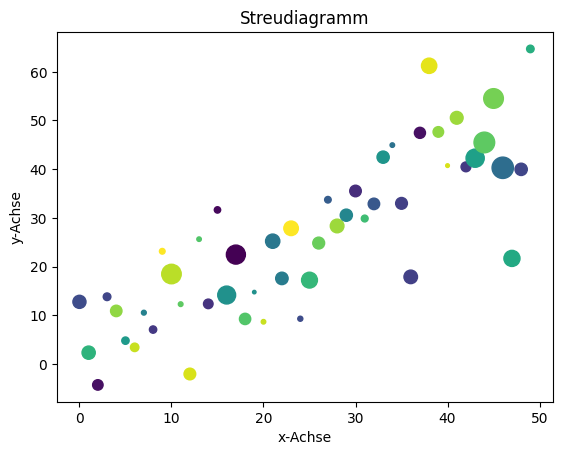

In [5]:
import numpy as np
import matplotlib.pyplot as plt


x = np.arange(50)
y = x + 10 * np.random.randn(50)
sizes = np.abs(np.random.randn(50)) * 100
color = np.random.randint(0, 50, 50),
plt.scatter(x,y, s=sizes, c=color)
plt.xlabel('x-Achse')
plt.ylabel('y-Achse')
plt.title('Streudiagramm')
plt.show()

### Aufgabe 6
Generieren Sie ein Streudiagramm, dass zwei Cluster darstellt. Beide Cluster sollen verschiedenfarbig dargestellt 
werden. Cluster-Center sind $(0,0)$ und $(1,1)$. Die Daten können Sie mit einem Zufallsgenerator erzeugen. 

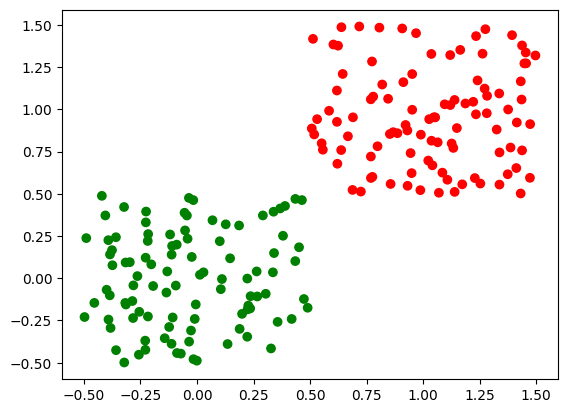